In [ ]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder 
from sklearn.tree import DecisionTreeClassifier
from sklearn.tree import plot_tree
from sklearn.metrics import accuracy_score
import matplotlib.pyplot as plt
print("Malavika Gireesh K")

Malavika Gireesh K


Accuracy: 0.9988571428571429

 feature Importance
             Feature  Importance
0      TotalQuantity         0.0
1      TotalSpending         1.0
2  PurchaseFrequency         0.0


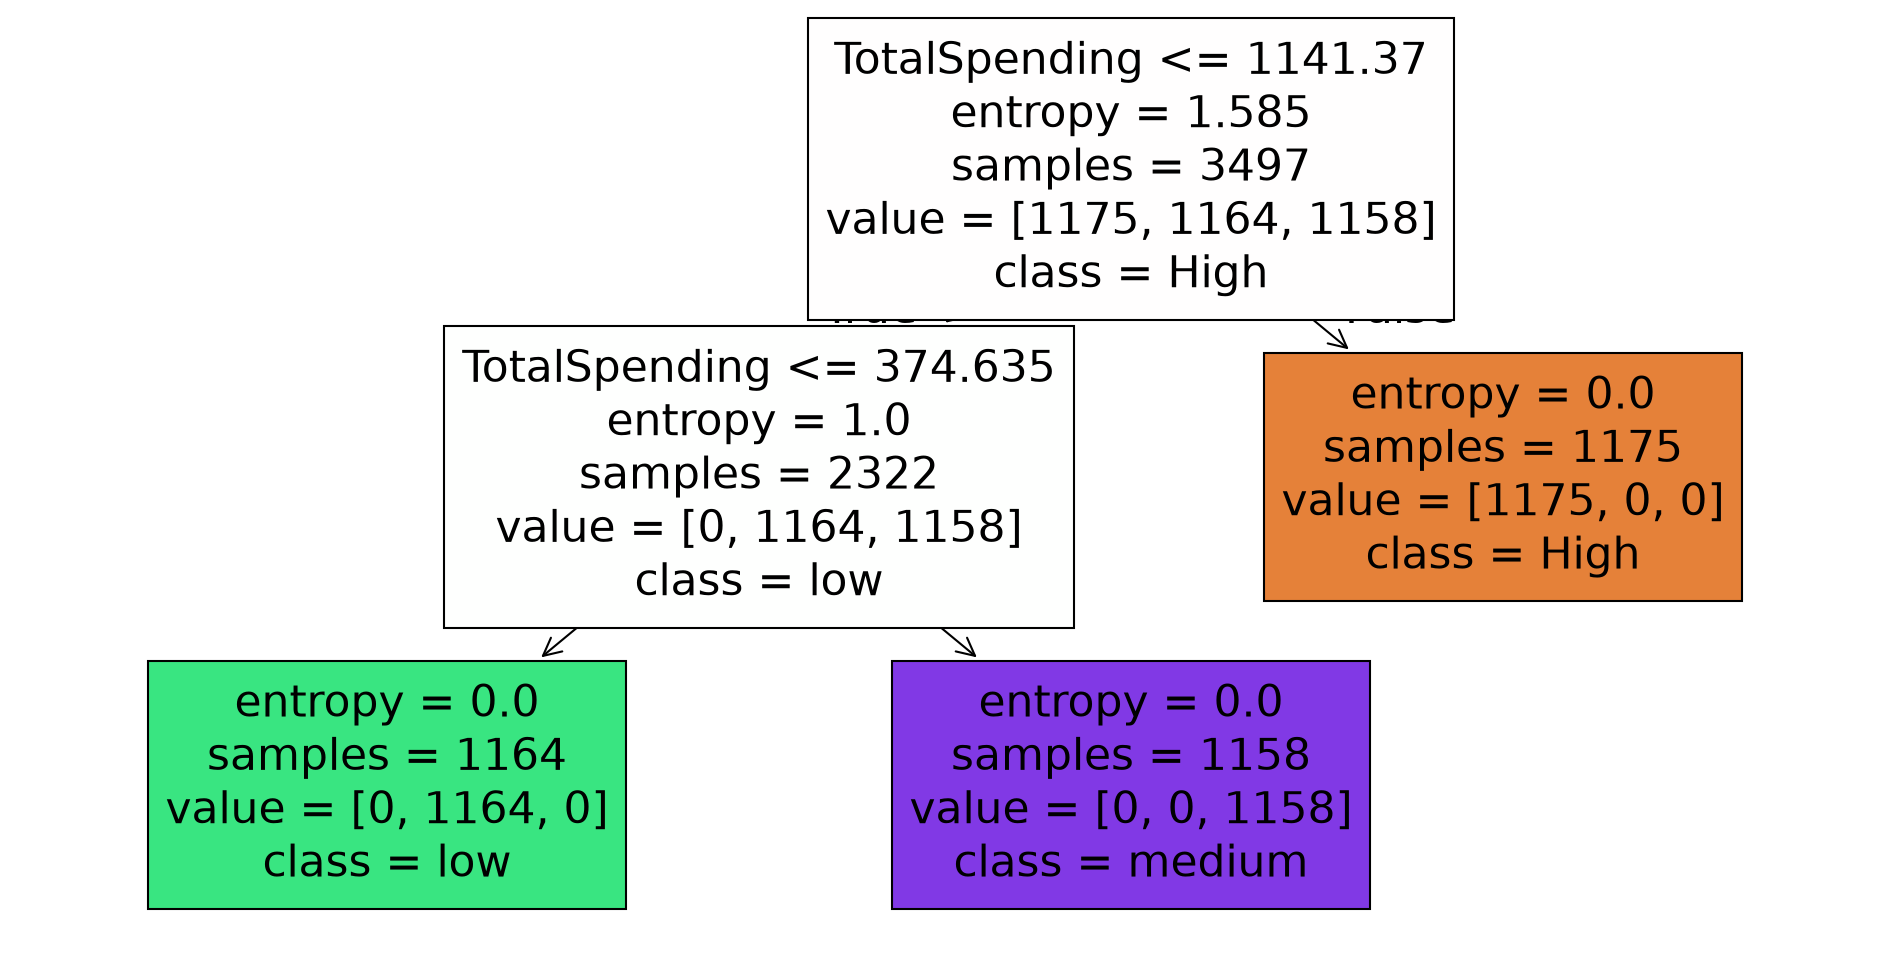

In [ ]:
df=pd.read_excel("OnlineRetail.xlsx")
df=df.dropna()
df["Total Amount"] = df["Quantity"]*df["UnitPrice"]
customer_data=df.groupby("CustomerID").agg({
    "Quantity":"sum",
    "Total Amount":"sum",
    "InvoiceNo":"nunique"
}).reset_index()
customer_data.columns=["CustomerID",
                       "TotalQuantity",
                       "TotalSpending",
                       "PurchaseFrequency"]
customer_data["Segment"]=pd.qcut(
    customer_data["TotalSpending"],
    q=3,
    labels=[
        "low",
        "medium",
        "High"]
)
X=customer_data[
    ["TotalQuantity",
     "TotalSpending",
     "PurchaseFrequency"]
    ]
y=customer_data["Segment"]
encoder=LabelEncoder()
y=encoder.fit_transform(y)
X_train,X_test,y_train,y_test=train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)
model=DecisionTreeClassifier(
    criterion="entropy",
    random_state=42)
model.fit(X_train,y_train)
y_pred=model.predict(X_test)
accuracy=accuracy_score(y_test,y_pred)
print("Accuracy:",accuracy)
importance=pd.DataFrame({
    "Feature":X.columns,
    "Importance":model.feature_importances_})
print("\n feature Importance")
print(importance)
plt.figure(figsize=(16,8))
plot_tree(
    model,
    feature_names=X.columns,
    class_names=encoder.classes_,
    filled=True)
plt.show()